# 01. Adult Census Income exploration

Phase 1 inspection of the pooled UCI Adult files. The notebook uses the project library and does not score the held-out test partition.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from data.load_data import load_adult_combined
from data.schema import CATEGORICAL_FEATURES, FEATURE_COLUMNS, NUMERIC_FEATURES, TARGET_COLUMN

loaded = load_adult_combined(ROOT / "data" / "raw")
adult = loaded.frame
print(f"rows={len(adult):,}  predictors={len(FEATURE_COLUMNS)}  rows_removed={loaded.metadata['rows_removed']}")
print(f"trailing periods normalized={loaded.metadata['trailing_period_labels']:,}")
adult.head(3)

rows=48,842  predictors=14  rows_removed=0
trailing periods normalized=16,281


,source_file,source_line,source_row_id,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,adult.data,1,adult.data:1,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,adult.data,2,adult.data:2,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,adult.data,3,adult.data:3,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K


In [2]:
class_counts = adult[TARGET_COLUMN].value_counts().rename("count").to_frame()
class_counts["percent"] = 100 * class_counts["count"] / len(adult)
missing = adult[FEATURE_COLUMNS].isna().sum().rename("missing_count").to_frame()
missing["missing_percent"] = 100 * missing["missing_count"] / len(adult)
display(class_counts)
display(missing.loc[missing["missing_count"] > 0])
print("numerical:", ", ".join(NUMERIC_FEATURES))
print("categorical:", ", ".join(CATEGORICAL_FEATURES))
print("labels:", sorted(adult[TARGET_COLUMN].unique()))

,count,percent
income,,
<=50K,37155,76.071823
>50K,11687,23.928177


,missing_count,missing_percent
workclass,2799,5.730724
occupation,2809,5.751198
native-country,857,1.754637


numerical: age, fnlwgt, education-num, capital-gain, capital-loss, hours-per-week
categorical: workclass, education, marital-status, occupation, relationship, race, sex, native-country
labels: ['<=50K', '>50K']


**class_distribution.png**

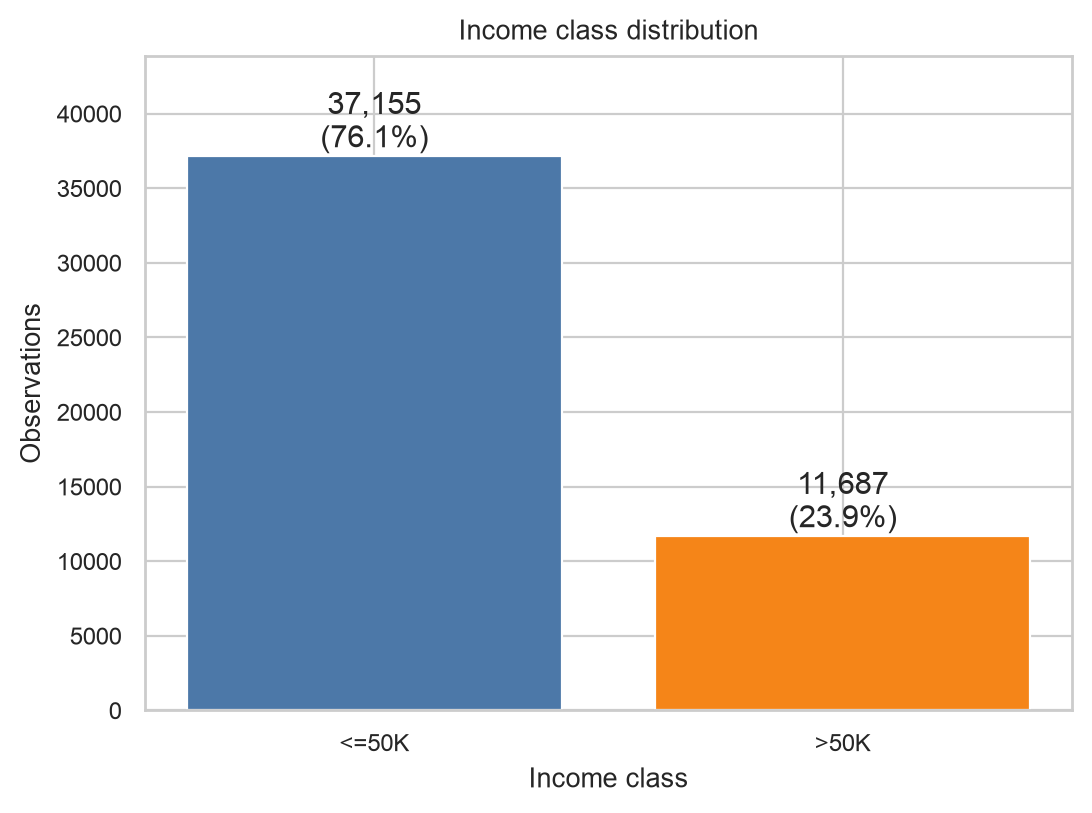

**missing_values.png**

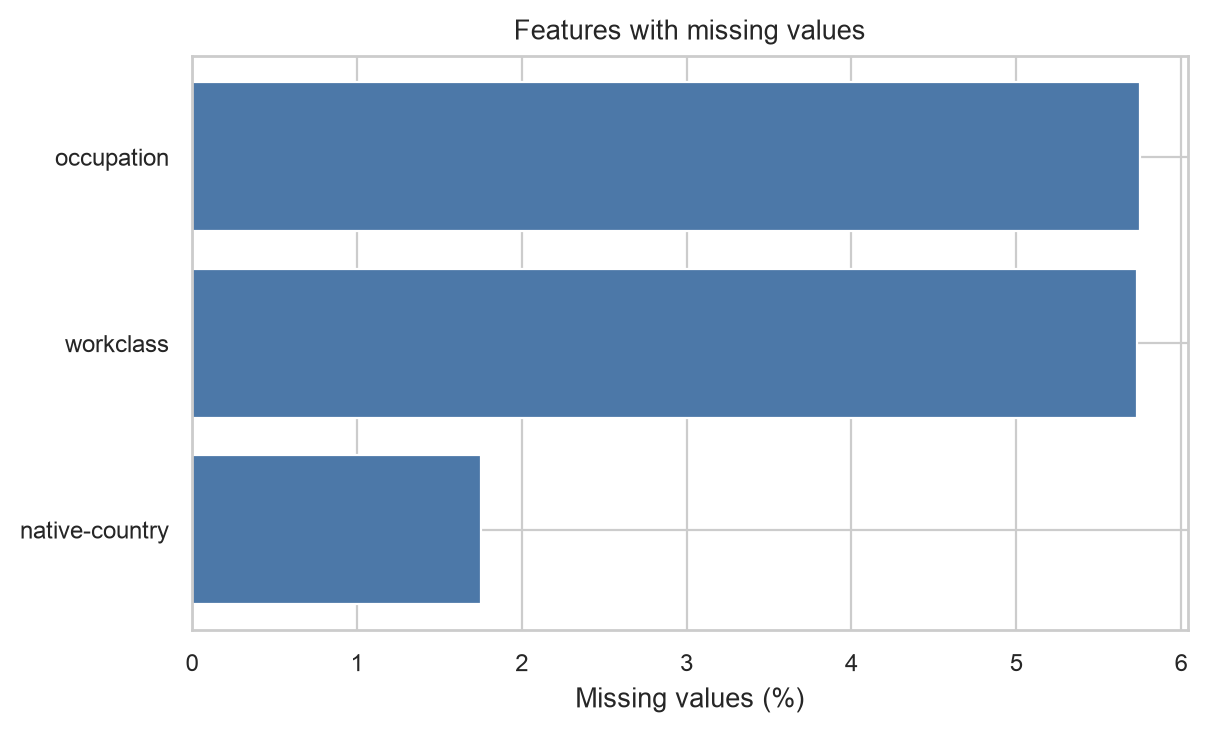

**numeric_by_income_training.png**

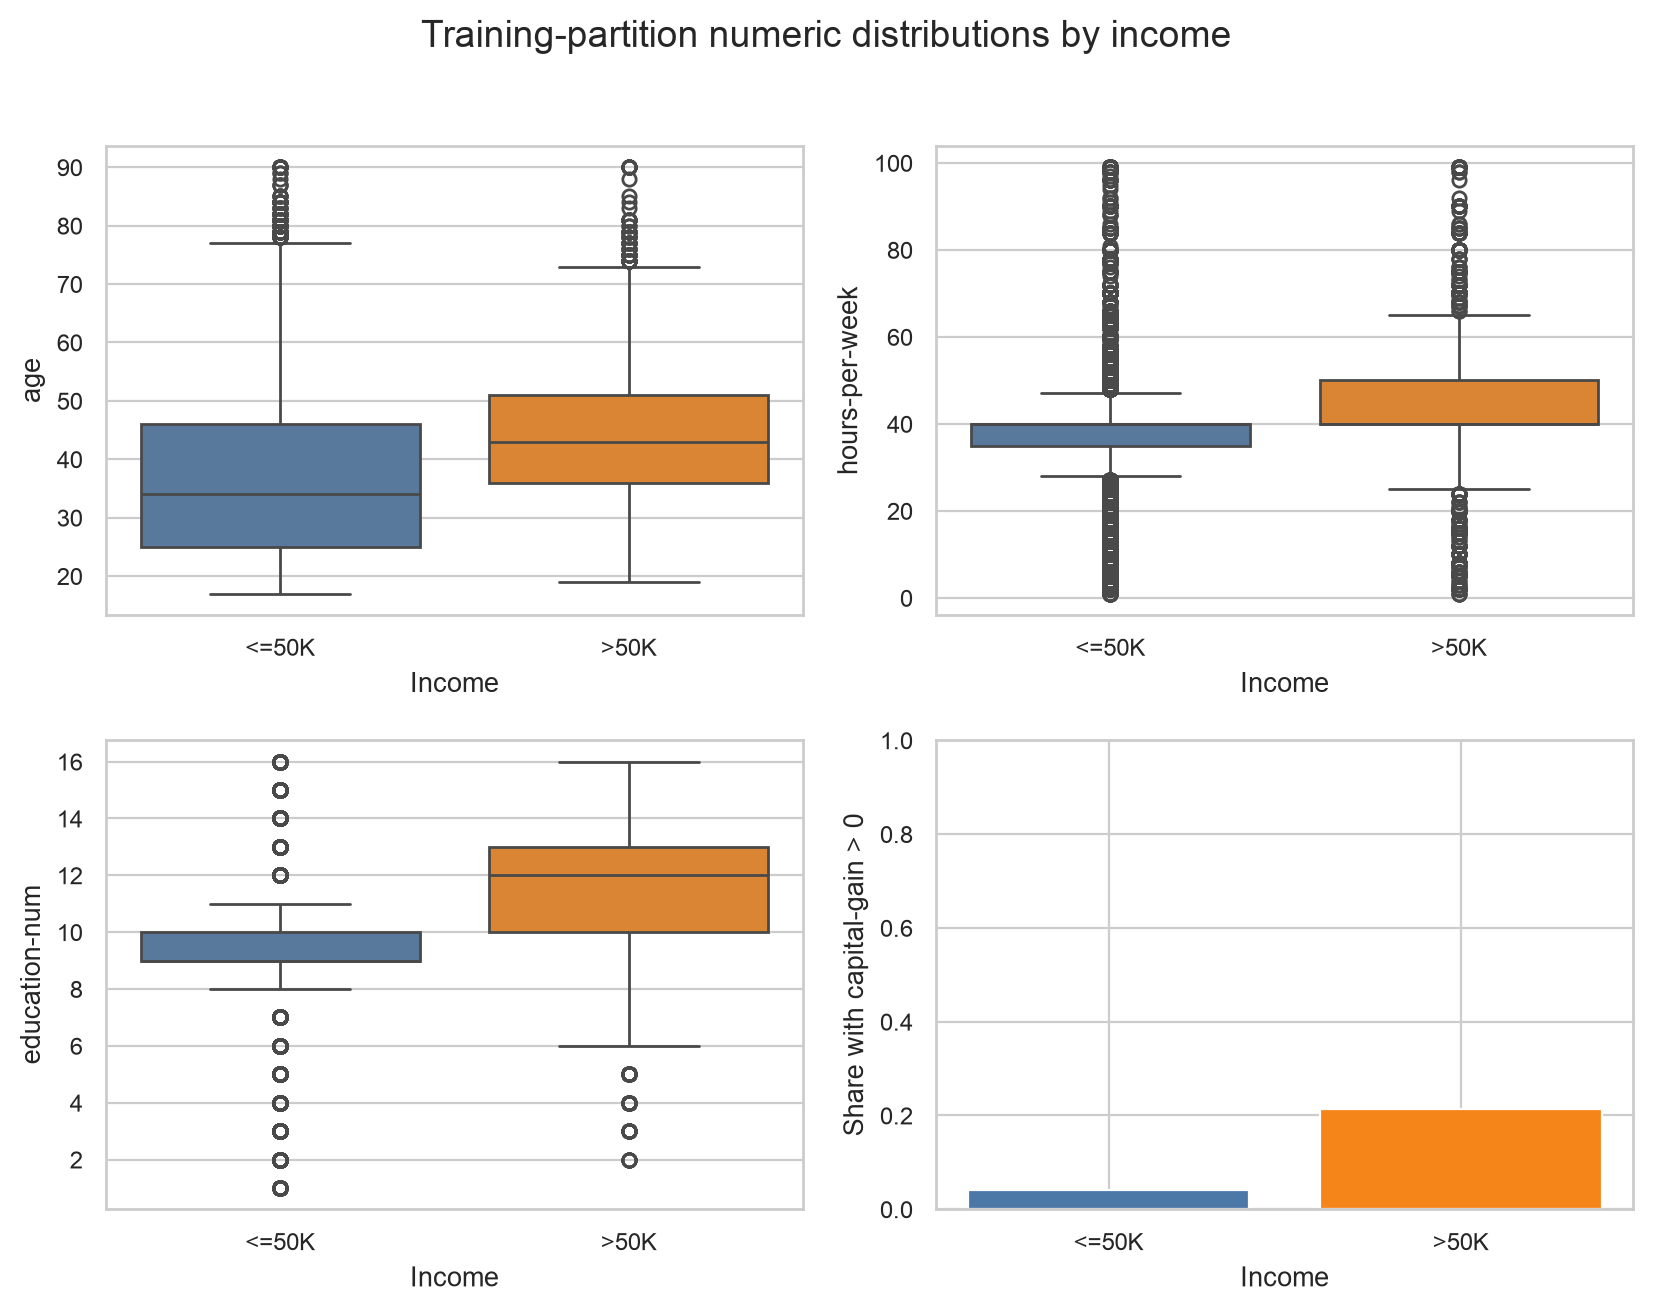

**correlation_heatmap_training.png**

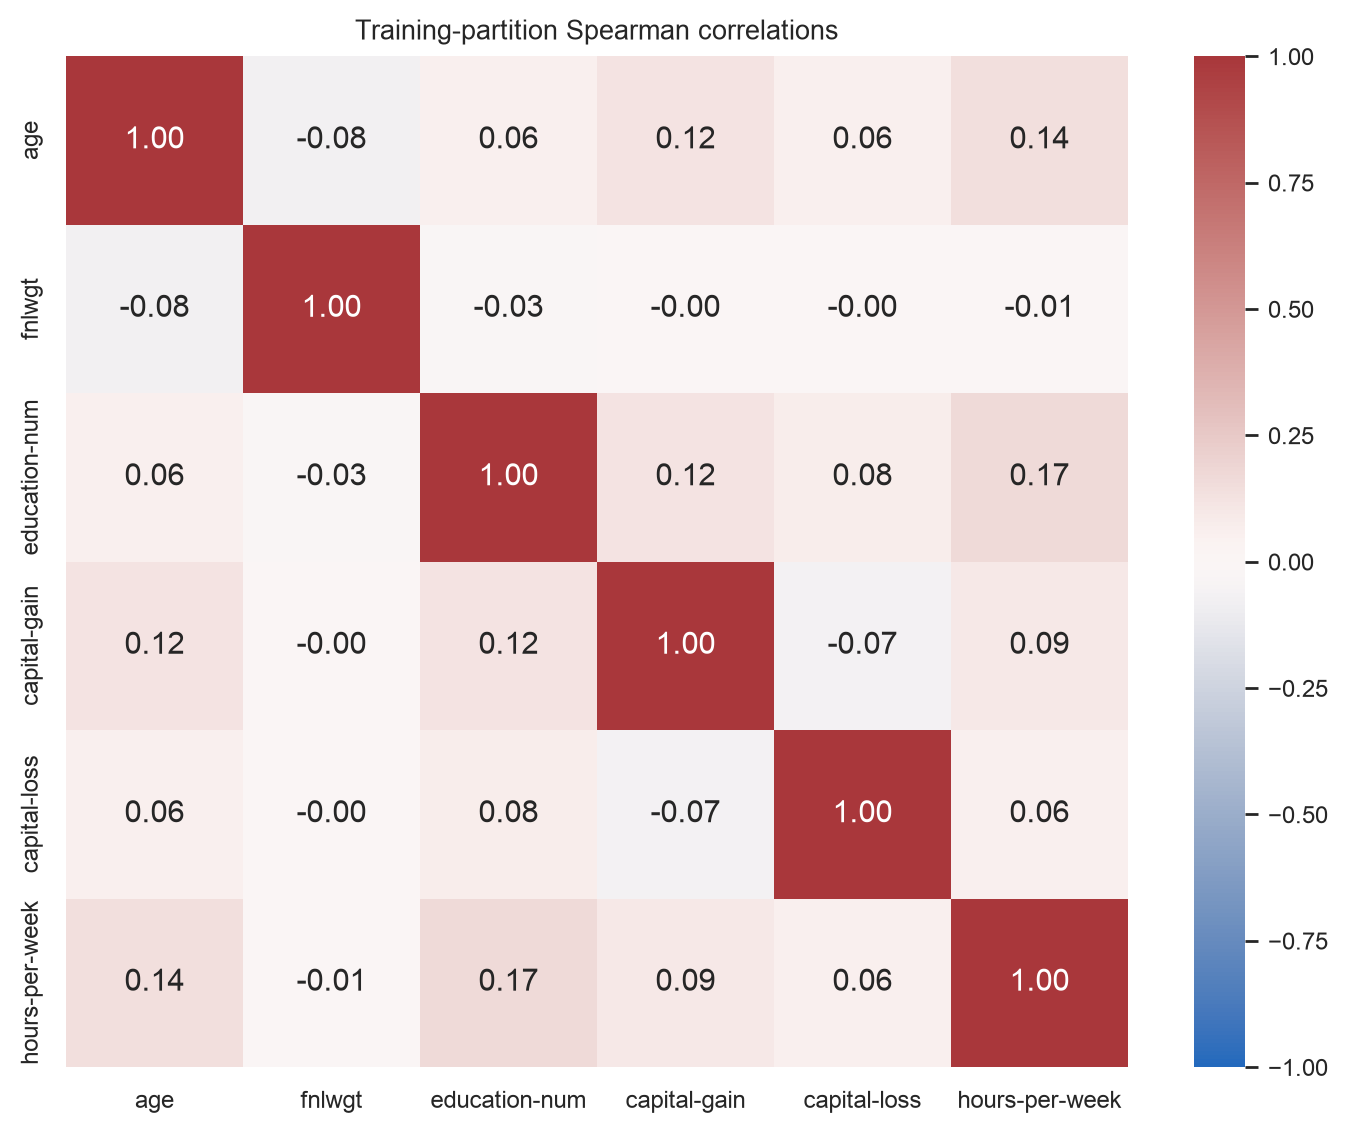

**income_rate_education_training.png**

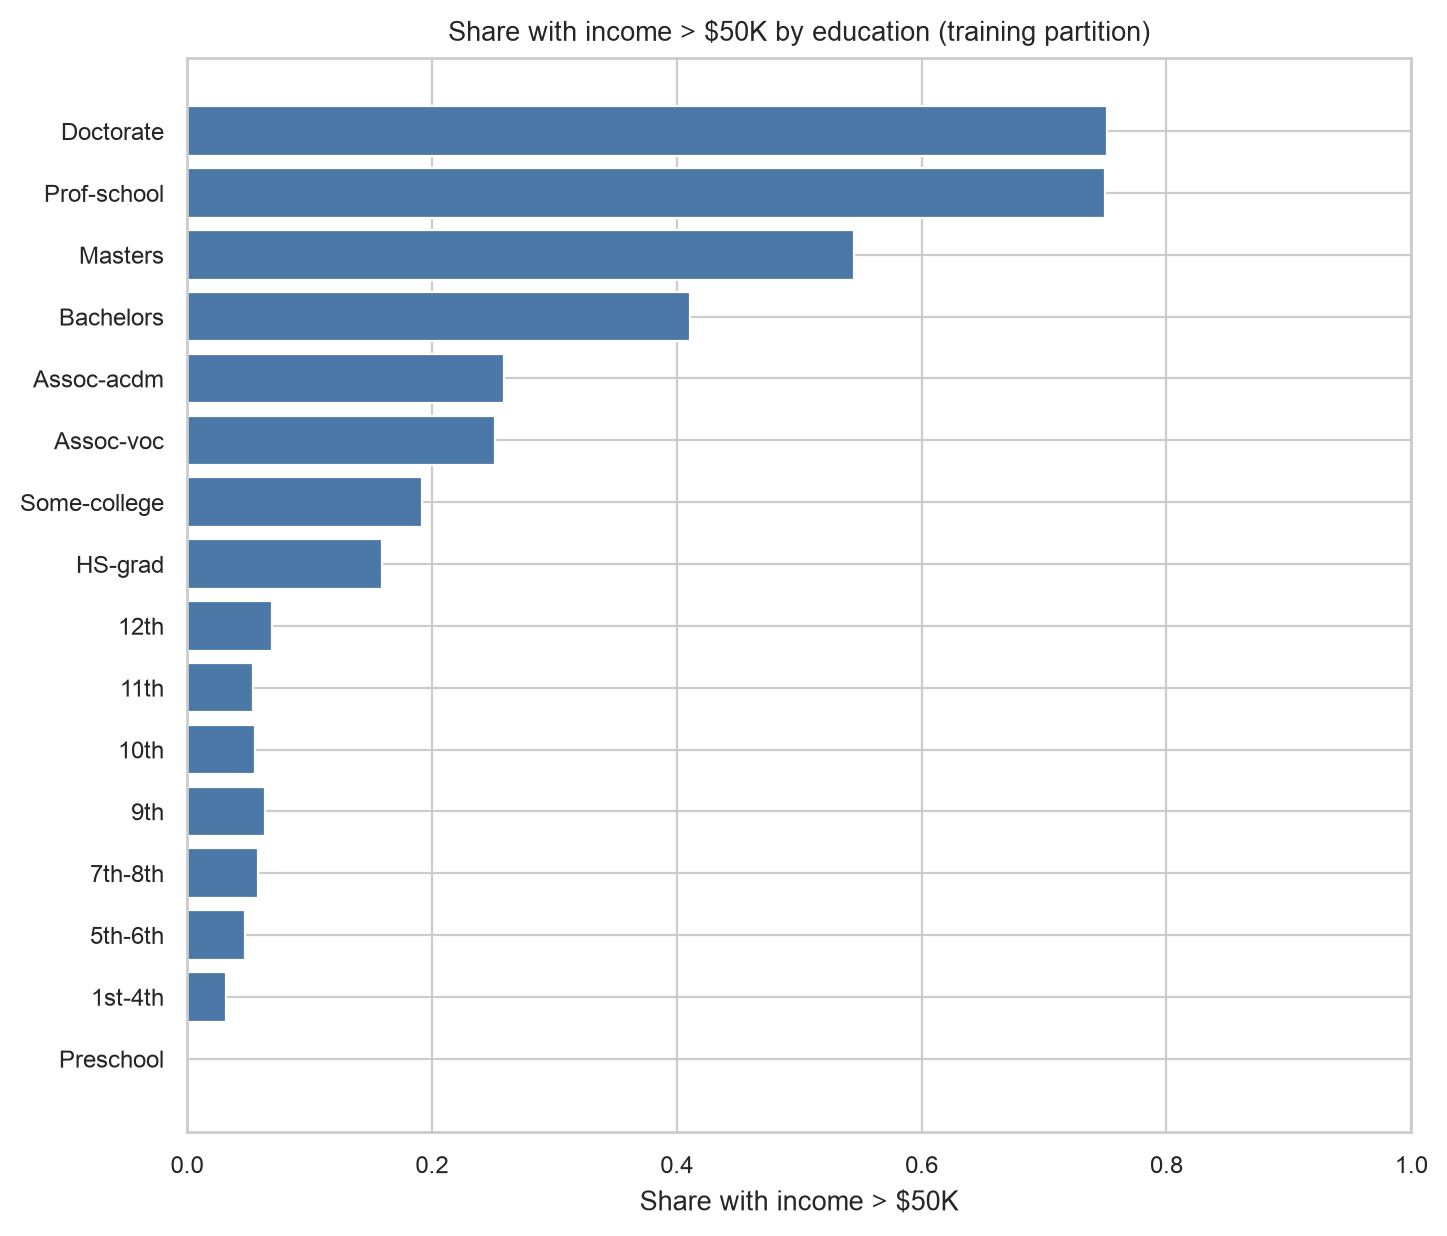

**income_rate_occupation_training.png**

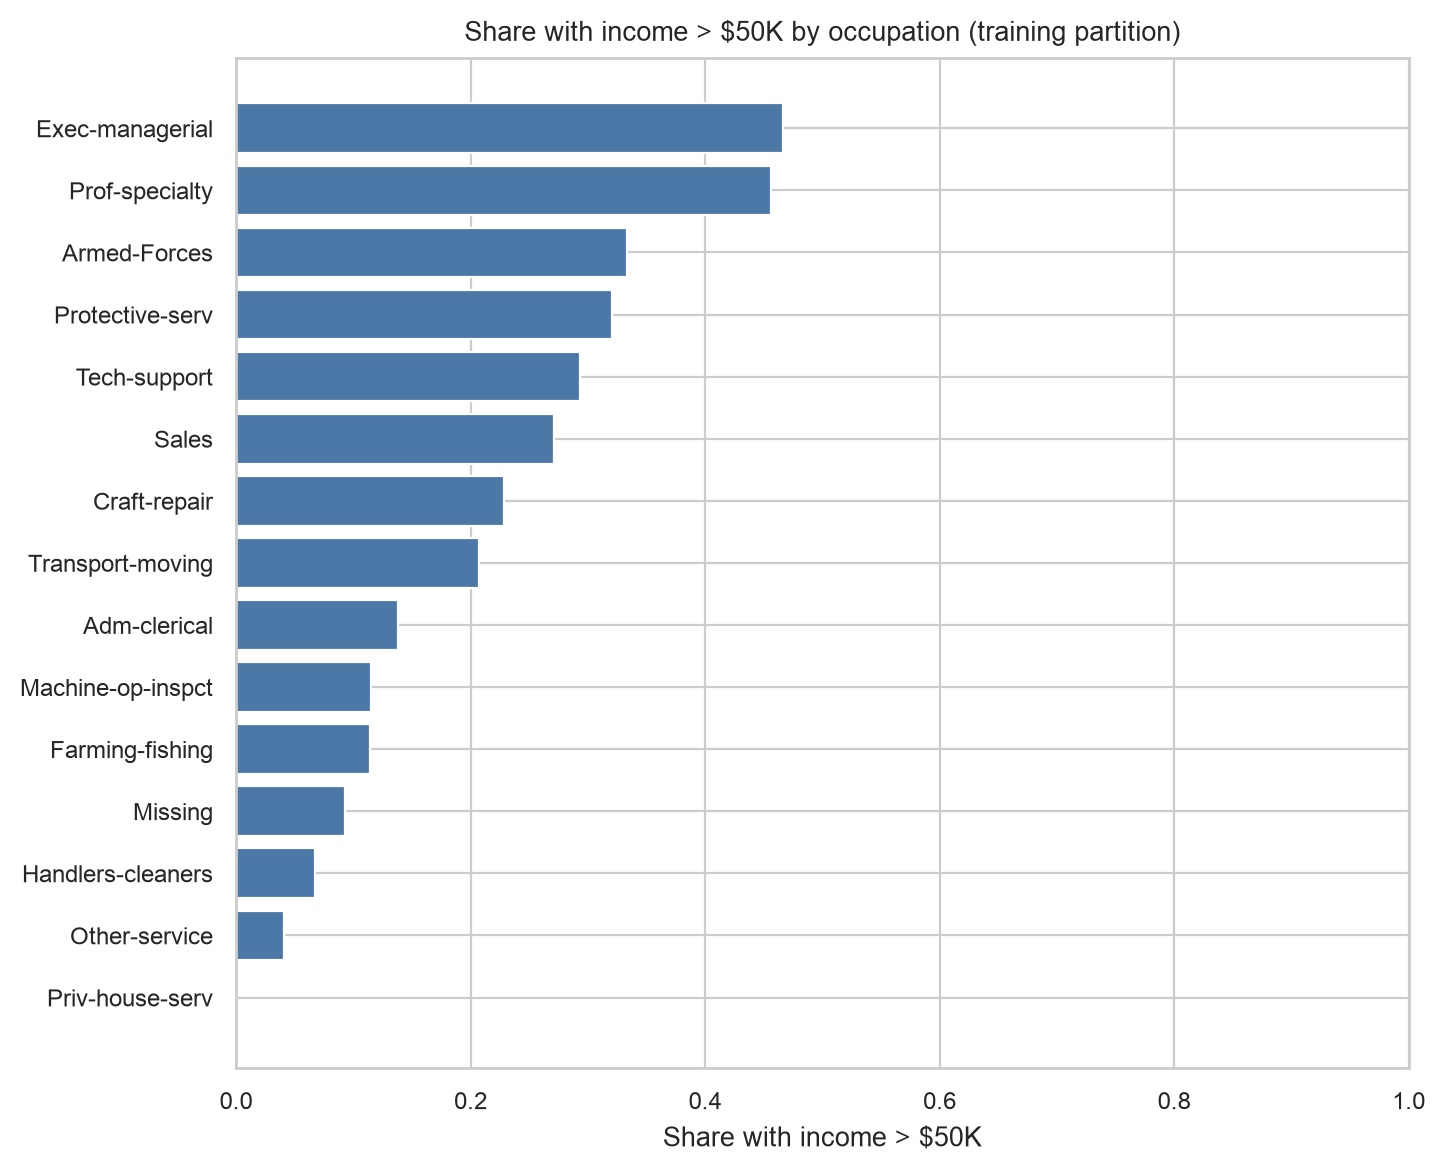

In [3]:
from IPython.display import Image, Markdown, display

figures = [
    "class_distribution.png",
    "missing_values.png",
    "numeric_by_income_training.png",
    "correlation_heatmap_training.png",
    "income_rate_education_training.png",
    "income_rate_occupation_training.png",
]
for name in figures:
    path = ROOT / "results" / "figures" / name
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(path)))